# 12 - Exact equations and substitutions

**MATH 331 - Differential Equations.** Lecture plan: Session 6 (Unit 3: exact equations, integrating factors, Bernoulli and homogeneous substitutions).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 1.8** (exact equations: Figure 1.8.1, Examples 1.8.2,
  1.8.3, 1.8.5-1.8.7, Theorem 1.8.1, Exercises 1.8.7-1.8.9) and **Section 1.5** (substitution:
  Examples 1.5.1 and 1.5.2, Exercise 1.5.7).
* Exercise numbers are those of the exercise lists at the end of each chapter of the
  LibreTexts edition, unless "in the text" is said.
* Prerequisites: videos R01-R03; notebooks 10 (separable equations, implicit solutions) and 11
  (linear equations).

**What you will learn**
1. An **exact** equation is a conserved quantity $F(x, y) = C$ in disguise; how to recognise one
   (a test) and how to find $F$.
2. How an **integrating factor** $\mu(x)$ or $\mu(y)$ makes an equation exact.
3. Two **substitutions** that turn a new equation into an old one: Bernoulli into linear,
   homogeneous into separable.

## 1. Theory in brief

**Partial derivatives.** For a function of two variables $F(x, y)$, $F_x = \dfrac{\partial F}{\partial x}$
is the derivative in $x$ with $y$ treated as a constant, and $F_y$ the derivative in $y$ with $x$
constant. Example: $F = x^2y$ has $F_x = 2xy$, $F_y = x^2$. The order does not matter:
$F_{xy} = F_{yx}$.

**Exact equations.** Along a solution $y(x)$ the quantity $F(x, y(x))$ stays constant when
$\dfrac{d}{dx}F(x, y(x)) = F_x + F_y\,y' = 0$. An equation

$$ M(x, y) + N(x, y)\,y' = 0 \qquad\text{(also written } M\,dx + N\,dy = 0\text{)} $$

is **exact** when $M = F_x$ and $N = F_y$ for some function $F$, the **potential**. Its solutions
are then the level curves $F(x, y) = C$: an implicit solution (notebook 10).

**The test.** If the equation is exact, then $M_y = N_x$.
*Proof:* $M_y = (F_x)_y = F_{xy} = F_{yx} = (F_y)_x = N_x$. $\square$
Conversely, if $M_y = N_x$ a potential exists, at least near each point (Lebl, Theorem 1.8.1).

**Finding $F$.** (1) Integrate $M$ in $x$: $F = \int M\,dx + A(y)$, with an unknown function of
$y$ in place of the constant. (2) Differentiate in $y$ and set equal to $N$: this gives $A'(y)$.
(3) Integrate to find $A$.

**Integrating factors.** If $M_y \ne N_x$, multiply the equation by a function $\mu$ chosen so
that it becomes exact:

* if $\dfrac{M_y - N_x}{N} = P$ depends on $x$ only, take $\mu(x) = e^{\int P\,dx}$;
* if $\dfrac{M_y - N_x}{M} = Q$ depends on $y$ only, take $\mu(y) = e^{-\int Q\,dy}$.

**Substitutions.**

| When you see | Try | You get |
|---|---|---|
| $y' + p(x)\,y = q(x)\,y^n$ (Bernoulli, $n \ne 0, 1$) | $v = y^{1-n}$ | a **linear** equation for $v$ |
| $y' = g\!\left(\dfrac{y}{x}\right)$ (homogeneous) | $v = \dfrac{y}{x}$, so $y' = v + x\,v'$ | a **separable** equation for $v$ |

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: slope_field, solution_curve, linear_first_order, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. A conserved quantity

*Lebl, Figure 1.8.1.* Take $F(x, y) = x^2 + y^2$. Its level curves $F = C$ are circles. Along a
circle $y(x)$, differentiating $x^2 + y^2 = C$ gives

$$ 2x + 2y\,y' = 0, \qquad\text{that is}\qquad y' = -\frac{x}{y} . $$

So the circles are the solutions of this equation: the equation says "$x^2 + y^2$ does not
change". Think of $F$ as an energy, and of the solutions as the motions that conserve it.

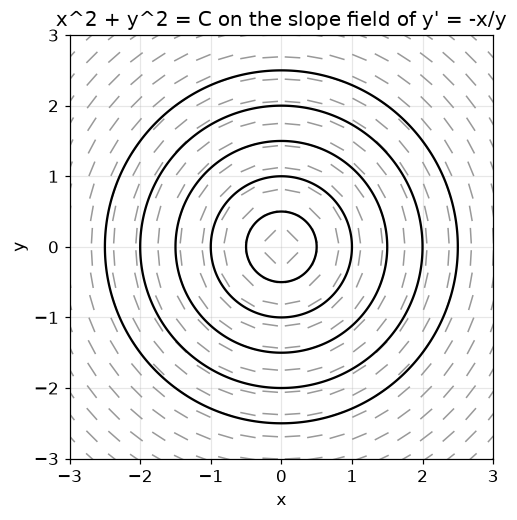

In [2]:
x, y, C = sp.symbols("x y C")


def residual(left, right=0):
    # left side minus right side of an equation, simplified: 0 for a solution (notebook 09)
    return sp.simplify(left - right)


def exactness(M, N):
    # M_y - N_x: zero for an exact equation  M + N y' = 0
    return sp.simplify(sp.diff(M, y) - sp.diff(N, x))


def slope_circles(x, y):
    return -x / y


SQUARE = (-3.0, 3.0)
FIGURE_SIZE = (6.0, 5.0)
WIDE_FIGURE = (7.0, 3.6)
GRID = 400                                    # even: the grids below do not contain 0
FIELD = 20                                    # even, for the same reason (the slope is -x/y)
RADII = (0.5, 1.0, 1.5, 2.0, 2.5)

grid_x, grid_y = np.meshgrid(np.linspace(*SQUARE, GRID), np.linspace(*SQUARE, GRID))

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, slope_circles, SQUARE, SQUARE, n=FIELD)
ax.contour(grid_x, grid_y, grid_x ** 2 + grid_y ** 2, levels=[radius ** 2 for radius in RADII],
           colors="black", linewidths=1.5)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("x^2 + y^2 = C on the slope field of y' = -x/y")
plt.show()

assert exactness(2 * x, 2 * y) == 0

*The plot shows* five circles centred at the origin (level curves of $x^2 + y^2$) on the slope
field of $y' = -x/y$. At every point the grey segment is tangent to the circle through that
point.

A circle is not the graph of one function: solving for $y$ gives the upper half
$y = \sqrt{C - x^2}$ or the lower half $y = -\sqrt{C - x^2}$. The initial condition decides, as
in notebook 10.

## 3. The test, and the potential, step by step

*Lebl, Example 1.8.3.* Solve $\;\dfrac{dy}{dx} = \dfrac{-2x - y}{x - 1}$, $\;y(0) = 1$.

Write it as $(2x + y) + (x - 1)\,y' = 0$: $M = 2x + y$, $N = x - 1$.

* **Test:** $M_y = 1$, $N_x = 1$. Exact.
* **Step 1:** $F = \int (2x + y)\,dx = x^2 + xy + A(y)$.
* **Step 2:** $F_y = x + A'(y)$ must be $N = x - 1$: $A'(y) = -1$.
* **Step 3:** $A = -y$, so $F = x^2 + xy - y$.
* **Constant:** $F(0, 1) = -1$, so the solution is $x^2 + xy - y = -1$.
* Here we can solve for $y$: $\;y = \dfrac{x^2 + 1}{1 - x}$, for $x < 1$.

The same steps with SymPy:

In [3]:
M, N = 2 * x + y, x - 1
print("test: M_y - N_x =", exactness(M, N))

step_1 = sp.integrate(M, x)                               # F up to a function A(y)
A_prime = sp.simplify(N - sp.diff(step_1, y))             # step 2
A = sp.integrate(A_prime, y)                              # step 3
F = step_1 + A
print("step 1:", step_1, "+ A(y)     step 2: A'(y) =", A_prime, "     F =", F)

level = F.subs({x: 0, y: 1})                              # the initial condition y(0) = 1
explicit = sp.solve(sp.Eq(F, level), y)[0]
print("C =", level, "     y =", sp.factor(explicit))

assert exactness(M, N) == 0 and residual(sp.diff(F, x), M) == 0 and residual(sp.diff(F, y), N) == 0
assert level == -1 and residual(explicit, (x ** 2 + 1) / (1 - x)) == 0
assert residual(M.subs(y, explicit) + N * sp.diff(explicit, x)) == 0       # it solves the equation

test: M_y - N_x = 0
step 1: x**2 + x*y + A(y)     step 2: A'(y) = -1      F = x**2 + x*y - y


C = -1      y = -(x**2 + 1)/(x - 1)


**An equation that fails the test.** *Lebl, Example 1.8.2:* $M = 2x + y$, $N = xy$.

In [4]:
print("M_y - N_x =", exactness(2 * x + y, x * y))
assert exactness(2 * x + y, x * y) != 0

M_y - N_x = 1 - y


$M_y - N_x = 1 - y \ne 0$: not exact. No potential $F$ exists, and the procedure above would
give nonsense (try it by hand: step 2 gives an "$A'(y)$" that still contains $x$).

## 4. Integrating factors $\mu(x)$ and $\mu(y)$

When the test fails, the equation can sometimes be **made** exact by multiplying it by a
function. You already did this in notebook 11: for a linear equation $y' + p\,y = f$, the factor
$r = e^{\int p\,dx}$ is exactly an integrating factor of the form $\mu(x)$.

The steps of Section 3 are collected in a function, to be used from now on.

In [5]:
def potential(M, N):
    # the potential F of an exact equation M + N y' = 0 (the three steps of Section 3)
    step_1 = sp.integrate(M, x)
    A_prime = sp.simplify(N - sp.diff(step_1, y))
    if A_prime.has(x):
        raise ValueError("the equation is not exact: A'(y) contains x")
    return sp.expand(step_1 + sp.integrate(A_prime, y))


assert residual(potential(2 * x + y, x - 1), F) == 0      # the example of Section 3

*Lebl, Example 1.8.6.* $\;\dfrac{x^2 + y^2}{x + 1} + 2y\,y' = 0$.

By hand: $M_y - N_x = \dfrac{2y}{x + 1} - 0 \ne 0$, not exact. But
$\dfrac{M_y - N_x}{N} = \dfrac{1}{x + 1}$ depends on $x$ only: $\mu(x) = e^{\int \frac{dx}{x+1}} = x + 1$.

In [6]:
M, N = (x ** 2 + y ** 2) / (x + 1), 2 * y
print("M_y - N_x       =", exactness(M, N))

P = sp.simplify(exactness(M, N) / N)
print("(M_y - N_x) / N =", P, "  (x only)")

mu = sp.simplify(sp.exp(sp.integrate(P, x)))
print("mu =", mu)
print("after multiplying: M_y - N_x =", exactness(mu * M, mu * N))

F_x = potential(sp.simplify(mu * M), sp.simplify(mu * N))
print("potential: F =", F_x)

assert mu == x + 1 and exactness(mu * M, mu * N) == 0
assert residual(F_x, x ** 3 / 3 + x * y ** 2 + y ** 2) == 0               # Lebl, Example 1.8.5

M_y - N_x       = 2*y/(x + 1)
(M_y - N_x) / N = 1/(x + 1)   (x only)
mu = x + 1
after multiplying: M_y - N_x = 0
potential: F = x**3/3 + x*y**2 + y**2


The solutions are $\tfrac13x^3 + xy^2 + y^2 = C$, that is
$y = \pm\sqrt{\dfrac{C - x^3/3}{x + 1}}$ (Lebl, Example 1.8.5).

*Lebl, Example 1.8.7.* $\;y^2 + (xy + 1)\,y' = 0$.

By hand: $M_y - N_x = 2y - y = y \ne 0$. Now $\dfrac{M_y - N_x}{N}$ contains both variables, but
$\dfrac{M_y - N_x}{M} = \dfrac1y$ depends on $y$ only: $\mu(y) = e^{-\int \frac{dy}{y}} = \dfrac1y$.

In [7]:
M, N = y ** 2, x * y + 1
print("M_y - N_x       =", exactness(M, N))
print("(M_y - N_x) / N =", sp.simplify(exactness(M, N) / N), "  (x and y: no mu(x))")

Q = sp.simplify(exactness(M, N) / M)
print("(M_y - N_x) / M =", Q, "  (y only)")

mu = sp.simplify(sp.exp(-sp.integrate(Q, y)))
print("mu =", mu)

F_y = potential(sp.expand(mu * M), sp.expand(mu * N))
print("potential: F =", F_y)

assert mu == 1 / y and exactness(mu * M, mu * N) == 0
assert residual(F_y, x * y + sp.log(y)) == 0

M_y - N_x       = y
(M_y - N_x) / N = y/(x*y + 1)   (x and y: no mu(x))
(M_y - N_x) / M = 1/y   (y only)
mu = 1/y
potential: F = x*y + log(y)


The solutions are $xy + \ln y = C$: **implicit**, it cannot be solved for $y$ with the functions you know. (Dividing by $y$ also
lost the constant solution $y = 0$: step 0 of notebook 10.) As in notebook 10,
we draw the level curves, follow one numerically, and compute a value with a root finder. Take
the solution through $(0, 1)$: there $F = 0$.

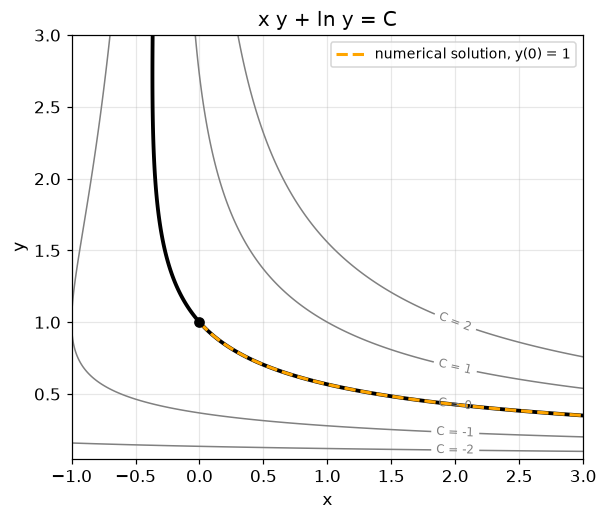

y(1) = 0.5671 (implicit relation), 0.5671 (numerical)


In [8]:
from scipy.optimize import brentq             # finds a root of a function between two points


def F_implicit(x, y):
    return x * y + np.log(y)


def slope_implicit(x, y):
    return -y ** 2 / (x * y + 1)              # y' from  y^2 + (x y + 1) y' = 0


X_WINDOW = (-1.0, 3.0)
Y_WINDOW = (0.05, 3.0)
RIGHT_HALF = (0.0, 3.0)                       # the numerical curve is followed to the right
LEVELS = (-2.0, -1.0, 0.0, 1.0, 2.0)
START = (0.0, 1.0)
X_TARGET = 1.0
BRACKET = (0.1, 1.0)                          # y(1) is between these two values
LABEL_X = 2.0                                 # the labels of the level curves are written here
LABEL_BRACKET = (1e-3, 10.0)

window_x, window_y = np.meshgrid(np.linspace(*X_WINDOW, GRID), np.linspace(*Y_WINDOW, GRID))

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
contours = ax.contour(window_x, window_y, F_implicit(window_x, window_y), levels=LEVELS,
                      colors="gray", linestyles="solid", linewidths=1)
label_points = [(LABEL_X, brentq(lambda value, c=c: F_implicit(LABEL_X, value) - c, *LABEL_BRACKET))
                for c in LEVELS]
ax.clabel(contours, fmt="C = %g", fontsize=8, manual=label_points)      # labels at x = LABEL_X
ax.contour(window_x, window_y, F_implicit(window_x, window_y), levels=[F_implicit(*START)],
           colors="black", linewidths=2.5)
x_curve, y_curve = ol.solution_curve(slope_implicit, START, RIGHT_HALF, Y_WINDOW)
ax.plot(x_curve, y_curve, "--", color="orange", linewidth=2, label="numerical solution, y(0) = 1")
ax.plot(*START, "o", color="black")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("x y + ln y = C")
ax.legend(loc="upper right")
plt.show()

y_implicit = brentq(lambda value: F_implicit(X_TARGET, value), *BRACKET)
y_numerical = np.interp(X_TARGET, x_curve, y_curve)
print(f"y({X_TARGET:.0f}) = {y_implicit:.4f} (implicit relation), {y_numerical:.4f} (numerical)")
assert np.isclose(y_implicit, y_numerical)

*The plot shows* the level curves of $xy + \ln y$ for five values of $C$ (thin grey lines) in the
half plane $y > 0$; each one decreases towards the $x$ axis on the right. The thick black curve
is the level $C = 0$, through the black dot $(0, 1)$. The dashed orange curve, computed
numerically from $y(0) = 1$ towards the right, lies exactly on it.

## 5. Bernoulli equations

*Lebl, Example 1.5.1.* $\;x\,y' + y\,(x + 1) + x\,y^5 = 0$, $\;y(1) = 1$.

In standard form, $y' + \dfrac{x + 1}{x}\,y = -y^5$: linear, except for the power $y^5$. It is a
**Bernoulli** equation with $n = 5$. Substitute $v = y^{1 - n} = y^{-4}$. By the chain rule,

$$ v' = -4\,y^{-5}\,y' = -4\,y^{-5}\Big(-\frac{x+1}{x}\,y - y^5\Big) = \frac{4(x+1)}{x}\,v + 4, $$

so

$$ v' - \frac{4(x + 1)}{x}\,v = 4, \qquad v(1) = 1^{-4} = 1 : $$

a **linear** equation (notebook 11). Its integral has no closed form, so we let
`ol.linear_first_order` compute it, and then go back: $y = v^{-1/4}$.

Three independent computations of the same solution: (1) the substitution; (2) `solve_ivp` on
the original equation; (3) the formula of Lebl (written here in an equivalent form),
$y = \Big(e^{4x}x^4\big(4\int_1^x \tfrac{e^{-4s}}{s^4}ds + e^{-4}\big)\Big)^{-1/4}$.

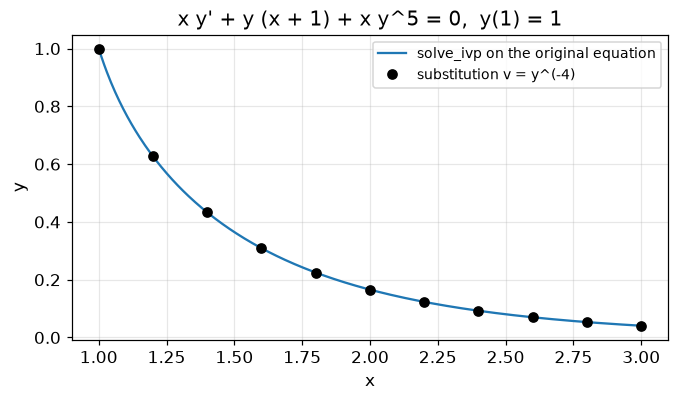

y(2) = 0.1654 (substitution), 0.1654 (solve_ivp), 0.1654 (Lebl's formula)


In [9]:
from scipy.integrate import quad              # a definite integral, numerically

POWER = 5                                     # the n of the Bernoulli equation
X_START, X_END = 1.0, 3.0
N_DOTS = 11
N_POINTS = 400
X_CHECK = 2.0
TOLERANCE = 1e-10


def p_linear(s):
    return -(POWER - 1) * (s + 1) / s


def f_linear(s):
    return float(POWER - 1)


def bernoulli_by_substitution(points):
    v = ol.linear_first_order(p_linear, f_linear, X_START, 1.0, points)
    return v ** (-1 / (POWER - 1))


def lebl_formula(point):
    integral = quad(lambda s: np.exp(-4 * s) / s ** 4, X_START, point)[0]
    return (np.exp(4 * point) * point ** 4 * (4 * integral + np.exp(-4))) ** -0.25


direct = solve_ivp(lambda s, value: -(s + 1) / s * value - value ** POWER, (X_START, X_END), [1.0],
                   dense_output=True, rtol=TOLERANCE, atol=TOLERANCE)

x_dots = np.linspace(X_START, X_END, N_DOTS)
x_fine = np.linspace(X_START, X_END, N_POINTS)

fig, ax = plt.subplots(figsize=WIDE_FIGURE)
ax.plot(x_fine, direct.sol(x_fine)[0], "-", label="solve_ivp on the original equation")
ax.plot(x_dots, bernoulli_by_substitution(x_dots), "o", color="black", label="substitution v = y^(-4)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("x y' + y (x + 1) + x y^5 = 0,  y(1) = 1")
ax.legend()
plt.show()

three_ways = (float(bernoulli_by_substitution(X_CHECK)), direct.sol(X_CHECK)[0], lebl_formula(X_CHECK))
print(f"y({X_CHECK:.0f}) = {three_ways[0]:.4f} (substitution), {three_ways[1]:.4f} (solve_ivp), "
      f"{three_ways[2]:.4f} (Lebl's formula)")
assert np.allclose(three_ways, three_ways[0])
assert np.allclose(bernoulli_by_substitution(x_dots), direct.sol(x_dots)[0])

*The plot shows* the solution decreasing quickly from 1 at $x = 1$ towards 0. The dots (found
through the substitution and the linear equation) lie on the curve (the original equation solved
numerically).

## 6. Homogeneous equations

*Lebl, Example 1.5.2.* $\;x^2 y' = y^2 + xy$, $\;y(1) = 1$.

Divide by $x^2$: $\;y' = \Big(\dfrac{y}{x}\Big)^2 + \dfrac{y}{x}$. The right-hand side depends
only on the ratio $y/x$: the equation is **homogeneous**. Substitute $v = y/x$, that is $y = xv$
and $y' = v + xv'$:

$$ v + x\,v' = v^2 + v \;\Longrightarrow\; x\,v' = v^2 \;\Longrightarrow\; \frac{dv}{v^2} = \frac{dx}{x}
\;\Longrightarrow\; -\frac1v = \ln|x| + C . $$

Separable (notebook 10). Going back, $y = xv = \dfrac{x}{-\ln|x| - C}$, and $y(1) = 1$ gives
$C = -1$:

$$ y = \frac{x}{1 - \ln x}, \qquad 0 < x < e . $$

(The interval: the solution must contain $x = 1$, and the denominator vanishes at $x = e$.)

**The picture of a homogeneous equation.** Since the slope depends only on $y/x$, it is the same
at all points of a **ray** through the origin: the isoclines (notebook 09) are rays.

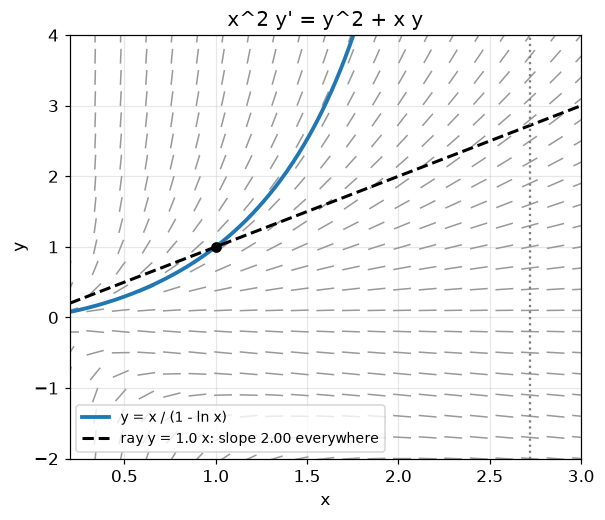

In [10]:
def slope_homogeneous(x, y):
    return (y / x) ** 2 + y / x


solution = x / (1 - sp.log(x))
assert residual(x ** 2 * sp.diff(solution, x), solution ** 2 + x * solution) == 0
assert solution.subs(x, 1) == 1

RAY_X = (0.2, 3.0)
RAY_Y = (-2.0, 4.0)
MARGIN = 0.02                                 # stop before the asymptote x = e
x_solution = np.linspace(RAY_X[0], np.e - MARGIN, N_POINTS)


def plot_ray(m=1.0):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ol.slope_field(ax, slope_homogeneous, RAY_X, RAY_Y)
    ax.plot(x_solution, x_solution / (1 - np.log(x_solution)), "-", linewidth=2.5,
            label="y = x / (1 - ln x)")
    ax.plot(RAY_X, [m * RAY_X[0], m * RAY_X[1]], "--", color="black", linewidth=2,
            label=f"ray y = {m:.1f} x: slope {m ** 2 + m:.2f} everywhere")
    ax.axvline(np.e, linestyle=":", color="gray")
    ax.plot(1.0, 1.0, "o", color="black")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("x^2 y' = y^2 + x y")
    ax.legend(loc="lower left")
    plt.show()


plot_ray()

*The plot shows* the slope field of the equation for $x > 0$, with the solution through the
black dot $(1, 1)$ (thick line), which rises more and more steeply and goes to infinity at the
dotted vertical line $x = e \approx 2.72$. The dashed black line is the ray $y = x$: all the grey
segments it crosses have the same slope, 2.

**Slider.** Before moving it: what is the slope along the ray $y = -x$? Along which rays is the
slope equal to the slope of the ray itself (so that the ray is a solution)?

In [11]:
RAY_RANGE = (-1.0, 2.0, 0.1)            # minimum, maximum, step

interact(plot_ray,
         m=FloatSlider(value=1.0, min=RAY_RANGE[0], max=RAY_RANGE[1], step=RAY_RANGE[2],
                       description="ray y = m x", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='ray y = m x', max=2.0, min=...

(Along $y = -x$ the slope is $1 - 1 = 0$. A ray $y = mx$ is a solution when $m^2 + m = m$, that
is only for $m = 0$: the $x$ axis.)

## 7. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

Which of these equations are exact? Use the test by hand, then type `True` or `False` for each,
in a list.

1. $(2x + y)\,dx + (x - 4y)\,dy = 0$ (*Lebl, Exercise 1.8.7(b)*)
2. $\Big(2y + \dfrac{y^2}{x}\Big)dx + (2y + x)\,dy = 0$ (*Lebl, Exercise 1.8.8(d)*)
3. $y\,dx - x\,dy = 0$
4. $e^{x}\,dx + e^{y}\,dy = 0$ (*Lebl, Exercise 1.8.7(c)*)

In [12]:
my_exact = None                 # for example [True, True, True, True]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 1", my_exact, [True, False, False, True]);

Exercise 1: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Lebl, Exercise 1.8.7(d).* Find a potential $F(x, y)$ of
$(3x^2 + 3y)\,dx + (3y^2 + 3x)\,dy = 0$. Type it as an expression in `x` and `y`. (A potential is
defined up to a constant: any constant is accepted.)

In [13]:
my_F = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

SAMPLES = 5
sample_x, sample_y = np.meshgrid(np.linspace(0.5, 2.5, SAMPLES), np.linspace(0.5, 2.5, SAMPLES))

if my_F is None:
    ol.check("Exercise 2a", None, 0.0)
else:
    expected_F = potential(3 * x ** 2 + 3 * y, 3 * y ** 2 + 3 * x)
    gap = sp.lambdify((x, y), my_F - expected_F, "numpy")(sample_x, sample_y) + 0 * sample_x
    ol.check("Exercise 2a", gap - gap[0, 0], np.zeros_like(sample_x));      # the gap must be a constant

Exercise 2a: no answer yet (replace None with your value)


**(b)** *Lebl, Exercise 1.8.8(d).* Find an integrating factor of
$\Big(2y + \dfrac{y^2}{x}\Big)dx + (2y + x)\,dy = 0$ (equation 2 of Exercise 1). Type it in place of
`None`: the cell multiplies the equation by your factor and applies the test.

In [14]:
my_mu = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

if my_mu is None:
    ol.check("Exercise 2b", None, 0.0)
else:
    after = exactness(my_mu * (2 * y + y ** 2 / x), my_mu * (2 * y + x))
    if after == 0 and sp.simplify(my_mu) != 0:
        print("Exercise 2b: correct")
    else:
        print("Exercise 2b: not yet (with your factor, M_y - N_x =", after, ")")

Exercise 2b: no answer yet (replace None with your value)


**(c)** *Lebl, Exercise 1.5.7.* Solve $x\,y' + y + y^2 = 0$, $y(1) = 2$ (which kind of equation is
it?). Type the solution as an expression in `x`.

In [15]:
my_y = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

X_INTERVAL = (1.0, 3.0)
expected_c = 2 / (3 * x - 2)                              # the answer printed in Lebl
assert residual(x * sp.diff(expected_c, x) + expected_c + expected_c ** 2) == 0
ol.check_formula("Exercise 2c", my_y, expected_c, x, X_INTERVAL);

Exercise 2c: no answer yet (replace None with your formula)


### Exercise 3 - Fill in

Complete the function `is_exact`: it must return `True` when $M_y = N_x$ and `False` otherwise.
One line is enough: look at `exactness` in Section 2, and remember that `==` compares.

In [16]:
def is_exact(M, N):
    return None                 # replace None with the formula

In [17]:
CASES = (((2 * x + y, x - 4 * y), True),                  # Exercise 1
         ((2 * y + y ** 2 / x, 2 * y + x), False),
         ((y, -x), False),
         ((sp.exp(x), sp.exp(y)), True),
         ((2 * x + y, x - 1), True),                      # Section 3
         ((2 * x + y, x * y), False),
         ((y ** 2, x * y + 1), False),                    # Section 4, before the factor
         ((y, x + 1 / y), True))                          # Section 4, after the factor

if is_exact(x, y) is None:
    print("Exercise 3: complete is_exact first")
else:
    try:
        answers = [bool(is_exact(M_case, N_case)) for (M_case, N_case), expected in CASES]
    except TypeError:
        answers = None
        print("Exercise 3: not yet (is_exact must return True or False: simplify M_y - N_x, then compare with == 0)")
    if answers is not None:
        for answer, ((M_case, N_case), expected) in zip(answers, CASES):
            assert answer == expected, f"wrong answer for M = {M_case}, N = {N_case}"
        print(f"Exercise 3: correct on all {len(CASES)} equations")

Exercise 3: complete is_exact first


### Exercise 4 - Explore

*Lebl, Exercise 1.8.9.* Every separable equation $y' = f(x)\,g(y)$ can be written as an exact
equation: $-f(x)\,dx + \dfrac{1}{g(y)}\,dy = 0$.

* Check with the test that it is exact (by hand: why is it obvious?).
* Do it for $y' = xy$: find the potential with `potential(M, N)`, draw some of its level curves
  (copy the plot of Section 4) and compare with the solutions $y = De^{x^2/2}$ of notebook 10.
* Take the linear equation of notebook 11, $y' + 2xy = e^{x - x^2}$, written as
  $(2xy - e^{x - x^2})\,dx + dy = 0$. Is it exact? And after multiplying by $r = e^{x^2}$?

In [18]:
# your code here

## 8. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. `[True, False, False, True]`. (1) $M_y = 1 = N_x$. (2) $M_y = 2 + 2y/x$, $N_x = 1$.
   (3) $M_y = 1$, $N_x = -1$. (4) $M_y = 0 = N_x$.
2. (a) $F = x^3 + 3xy + y^3$ (plus any constant). (b) $\mu = x$ (or any constant multiple):
   $(M_y - N_x)/N = 1/x$. (c) Bernoulli with $n = 2$ (also separable): $y = \dfrac{2}{3x - 2}$.
3. `return sp.simplify(sp.diff(M, y) - sp.diff(N, x)) == 0`, or `return exactness(M, N) == 0`.
4. $M = -f(x)$ does not contain $y$ and $N = 1/g(y)$ does not contain $x$: $M_y = 0 = N_x$. For
   $y' = xy$: $F = -\tfrac{x^2}{2} + \ln y$, and $F = C$ is $y = e^{C}e^{x^2/2}$. The linear
   equation is not exact ($M_y - N_x = 2x$); multiplied by $e^{x^2}$ it is: the integrating
   factor of notebook 11 is an integrating factor in the sense of this notebook.

</details>

**Where to go next:** notebook 13 (first-order models, Sessions 7 and 8: cooling, mixing tanks,
falling bodies, circuits) uses the methods of notebooks 10-12; notebook 03 (the logistic equation) is a
Bernoulli equation.